In [2]:
import numpy as np
from matplotlib import pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

import dill

In [3]:
#device = "cuda" if torch.cuda.is_available() else "cpu"
device ="cpu"
print(f"Using {device} device")

Using cpu device


---

In [4]:
#def sigmoid(x):
#    x = torch.tensor(x)
#    return nn.functional.sigmoid(x).detach().numpy()

#def sigmoid(x):
#    return 1/(1+np.exp(-x))

# https://qiita.com/chersky/items/d74c9662a25c4e84565f
def sigmoid(x):
    return np.exp(np.minimum(x, 0)) / (1 + np.exp(- np.abs(x)))

In [5]:
def softplus(x,beta=1.0):
    return np.log(1+np.exp(beta*x))/beta
def bsoftplus(x,beta=1.0,gamma=-2.0):
    return softplus(x,beta=beta) + gamma

In [6]:
def shifted_relu(x, gamma=0.5):
    return np.maximum(0, x) - gamma

In [7]:
def siglu(x, gamma=-0.5):
    return torch.where(x>0, x+gamma, torch.sigmoid(2*x/gamma)*(2*gamma))

---
## Sigmoid

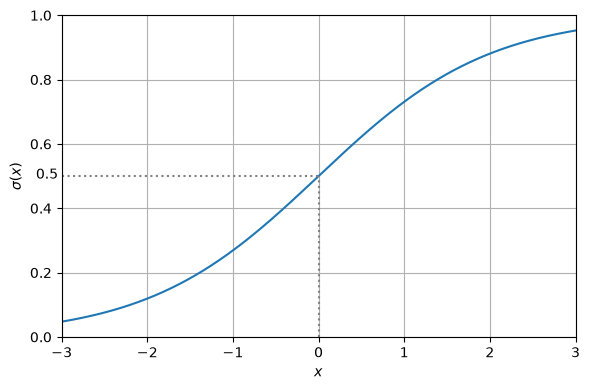

In [8]:
xx = np.linspace(-3,3,4000)

plt.figure(figsize=(6, 4))

plt.plot(xx,sigmoid(xx))
plt.xlim(-3,3)

plt.hlines(y=0.5,xmin=-3.0,xmax=0.0,linestyles='dotted',colors='gray')
plt.text(-3.3,0.49,r'$0.5$')

plt.vlines(x=0,ymin=-0.0,ymax=0.5,linestyles='dotted',colors='gray')
plt.ylim(0,1)

plt.xlabel(r'$x$')
plt.ylabel(r'$\sigma(x)$')
plt.xticks(np.arange(-3,4))
plt.grid()
plt.tight_layout()
plt.savefig('Sec4_Fig_Sigmoid1.pdf', bbox_inches='tight',transparent=True)
plt.show()

|w|=0.3,v1=4.333333333333334,v2=2.3333333333333335
|w|=0.2,v1=6.0,v2=4.0
|w|=0.1,v1=11.0,v2=9.0


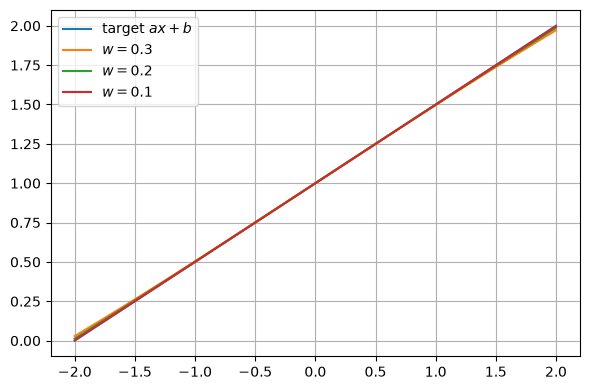

In [19]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値

# l(x) = v1 sigma(wx)-v2 sigma(-wx)
def calc_v_sigmoid(a,b,w):
    v = 4*a/w
    v1 = v/2 + b
    v2 = v/2 -b
    return v1,v2,w

plt.figure(figsize=(6, 4))
plt.plot(xx,a*xx+b,label='target $ax+b$')

w0 = [0.3,0.2,0.1]

for w in w0:
    v1,v2,w = calc_v_sigmoid(a,b,w)
    print(f'|w|={w},v1={v1},v2={v2}')
    plt.plot(xx,v1*sigmoid(w*xx)-v2*sigmoid(-w*xx),label=rf'$w={w}$')

plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig('Sec4_Fig_Sigmoid2.pdf', bbox_inches='tight',transparent=True)
plt.show()

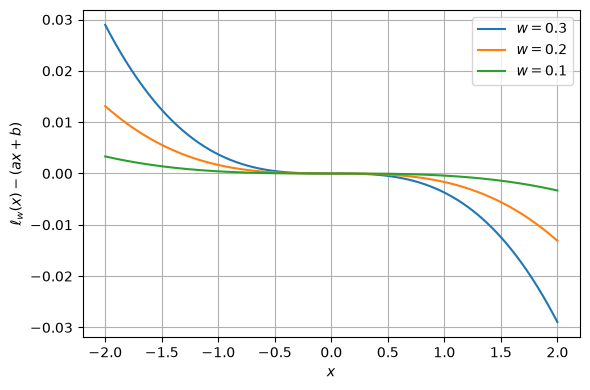

In [9]:
xx = np.linspace(-2,2,1000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値

# l(x) = v1 sigma(wx)-v2 sigma(-wx)
def calc_v_sigmoid(a,b,w):
    v = 4*a/w
    v1 = v/2 + b
    v2 = v/2 -b
    return v1,v2,w

#plt.plot(xx,a*xx+b,label='target $ax+b$')

w0 = [0.3,0.2,0.1]

plt.figure(figsize=(6, 4))
for w in w0:
    v1,v2,nw = calc_v_sigmoid(a,b,w)
    y = v1*sigmoid(w*xx)-v2*sigmoid(-w*xx)
    plt.plot(xx,y-(a*xx+b),label=rf'$w={w}$')

#plt.axhline(0.0, linewidth=1)
plt.xlabel(r'$x$')
plt.ylabel(r'$\ell_w(x) - (ax+b)$')
#plt.title(r'Pointwise error on $[-2,2]$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('Sec4_Fig_Sigmoid3.pdf', bbox_inches='tight',transparent=True)
plt.show()

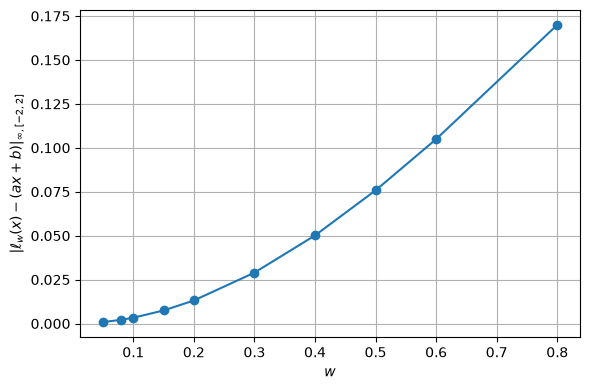

In [10]:
xx = np.linspace(-2,2,4000)

w0 = np.array([0.8, 0.6, 0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.08, 0.05])

errors = []
for w in w0:
    v1,v2,w = calc_v_sigmoid(a,b,w)
    y = v1*sigmoid(w*xx)-v2*sigmoid(-w*xx)
    err = np.max(np.abs(y-(a*xx+b)))
    errors.append(err)

errors = np.array(errors)

plt.figure(figsize=(6, 4))
plt.plot(w0, errors, marker='o')
plt.xlabel(r'$w$')
plt.ylabel(r'$|\ell_w(x)-(ax+b)|_{\infty,[-2,2]}$')
#plt.title(r'Supremum error versus scaling parameter $w$')
plt.grid(True)
plt.tight_layout()
plt.savefig('Sec4_Fig_Sigmoid4.pdf', bbox_inches='tight',transparent=True)
plt.show()

## Softplus

$v_0 > |\beta|$を満たすように大きく取らなければならないことに注意

$\beta = b/d = b/\phi(0)$

$a\ne0$

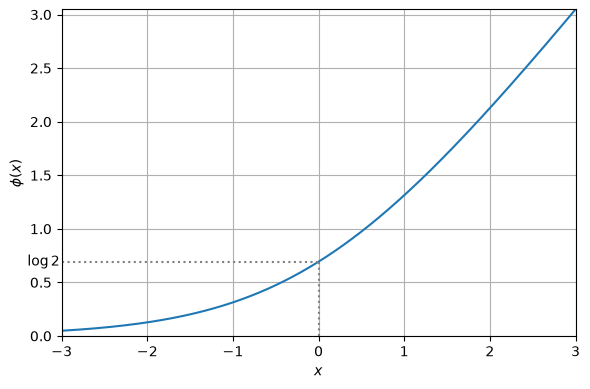

In [11]:
xx = np.linspace(-3,3,4000)

plt.figure(figsize=(6, 4))

plt.plot(xx,softplus(xx))
plt.xlim(-3,3)

plt.hlines(y=np.log(2),xmin=-3,xmax=0.0,linestyles='dotted',colors='gray')
plt.text(-3.4,np.log(2)-0.04,r'$\log2$')

plt.vlines(x=0,ymin=-0.0,ymax=np.log(2),linestyles='dotted',colors='gray')
plt.ylim(0,softplus(3))

plt.xlabel(r'$x$')
plt.ylabel(r'$\phi(x)$')
plt.xticks(np.arange(-3,4))
plt.grid()
plt.tight_layout()
plt.savefig('Sec4_Fig_Softplus1.pdf', bbox_inches='tight',transparent=True)
plt.show()

(w1,w2)=(0.25000,0.89717),(v1,v2)=(2.00000,-0.55730)
(w1,w2)=(0.16667,0.32107),(v1,v2)=(3.00000,-1.55730)
(w1,w2)=(0.12500,0.19552),(v1,v2)=(4.00000,-2.55730)
(w1,w2)=(0.10000,0.14056),(v1,v2)=(5.00000,-3.55730)


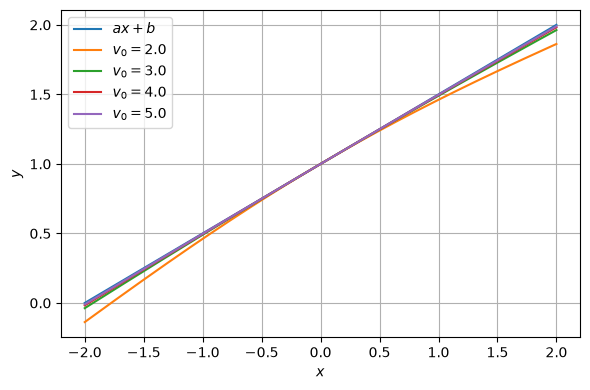

In [12]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値


def calc_v(a,b,v0):
    q = 1 #1/2+1/2
    d = np.log(2) #phi(0)
    alpha = a/q
    beta = b/d
    tau = np.sign(a)

    v1 = tau*v0
    v2 = beta-v1

    w1 = alpha/v1
    w2 = -alpha/v2

    
    return v1,v2,w1,w2

plt.figure(figsize=(6, 4))
plt.plot(xx,a*xx+b,label=r'$ax+b$') #r文字列はlatex表記でつかうバックスラッシュに対応するために必要

v0 = [2.0,3.0,4.0,5.0]

for v in v0:
    v1,v2,w1,w2 = calc_v(a,b,v)
    print(f'(w1,w2)=({w1:.5f},{w2:.5f}),(v1,v2)=({v1:.5f},{v2:.5f})')
    plt.plot(xx,v1*softplus(w1*xx)+v2*softplus(-w2*xx),label=rf'$v_0={v}$')


plt.xlabel(r'$x$')
plt.ylabel(r'$y$')
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig('Sec4_Fig_Softplus2.pdf', bbox_inches='tight',transparent=True)
plt.show()

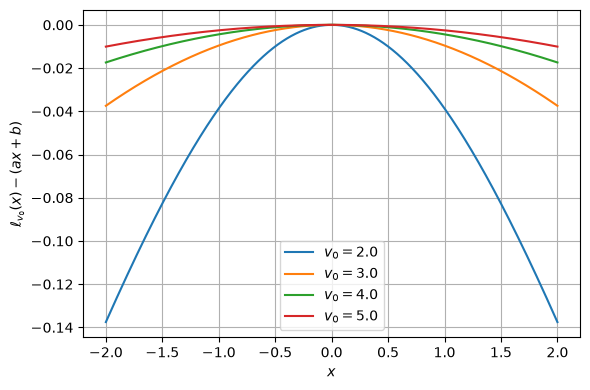

In [13]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値


def calc_v(a,b,v0):
    q = 1 #1/2+1/2
    d = np.log(2) #phi(0)
    alpha = a/q
    beta = b/d
    tau = np.sign(a)

    v1 = tau*v0
    v2 = beta-v1

    w1 = alpha/v1
    w2 = -alpha/v2

    return v1,v2,w1,w2


v0 = [2.0,3.0,4.0,5.0]

plt.figure(figsize=(6, 4))
for v in v0:
    v1,v2,w1,w2 = calc_v(a,b,v)
    y = v1*softplus(w1*xx)+v2*softplus(-w2*xx)
    plt.plot(xx,y-(a*xx+b),label=rf'$v_0={v}$')

#plt.axhline(0.0, linewidth=1)
plt.xlabel(r'$x$')
plt.ylabel(r'$\ell_{v_0}(x) - (ax+b)$')
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig('Sec4_Fig_Softplus3.pdf', bbox_inches='tight',transparent=True)
plt.show()

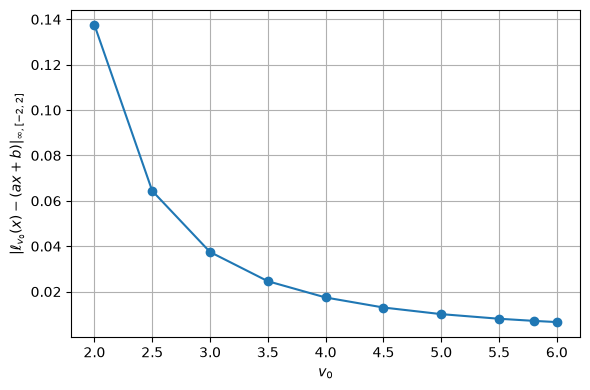

In [14]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値


def calc_v(a,b,v0):
    q = 1 #1/2+1/2
    d = np.log(2) #phi(0)
    alpha = a/q
    beta = b/d
    tau = np.sign(a)

    v1 = tau*v0
    v2 = beta-v1

    w1 = alpha/v1
    w2 = -alpha/v2

    return v1,v2,w1,w2


v0 = [2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,5.8,6.0]

errors=[]
for v in v0:
    v1,v2,w1,w2 = calc_v(a,b,v)
    y = v1*softplus(w1*xx)+v2*softplus(-w2*xx)
    err = np.max(np.abs(y-(a*xx+b)))
    errors.append(err)

errors = np.array(errors)

plt.figure(figsize=(6, 4))
plt.plot(v0, errors, marker='o')
plt.xlabel(r'$v_0$')
plt.ylabel(r'$|\ell_{v_0}(x)-(ax+b)|_{\infty,[-2,2]}$')
#plt.title(r'Supremum error versus scaling parameter $w$')
plt.grid(True)
plt.tight_layout()
plt.savefig('Sec4_Fig_Softplus4.pdf', bbox_inches='tight',transparent=True)
plt.show()

---

## Shifted ReLU

$v_0 > |\beta|$を満たすように大きく取らなければならないことに注意

$\beta = b/d = b/\phi(0)$

$a\ne0$

$\phi(x) = \operatorname{SReLU}(x) = \max(x,0)-\gamma$

$\gamma=0.5$

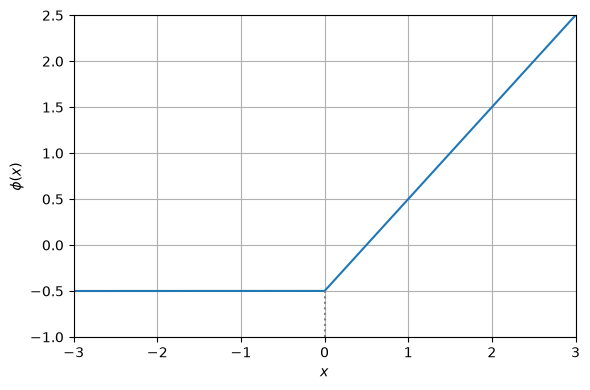

In [15]:
xx = np.linspace(-3,3,4000)

plt.figure(figsize=(6, 4))

plt.plot(xx,shifted_relu(xx,0.5)) # y=ReLU(x)-0.5
plt.xlim(-3,3)

#plt.hlines(y=-0.5,xmin=-3,xmax=0.0,linestyles='dotted',colors='gray')
#plt.text(-3.4,-0.5,r'$-0.5$')

plt.vlines(x=0,ymin=-1.0,ymax=-0.5,linestyles='dotted',colors='gray')
plt.ylim(-1,shifted_relu(3,0.5))

plt.xlabel(r'$x$')
plt.ylabel(r'$\phi(x)$')
plt.xticks(np.arange(-3,4))
plt.grid()
plt.tight_layout()
plt.savefig('Sec4_Fig_ShiftedReLU1.pdf', bbox_inches='tight',transparent=True)
plt.show()

(w1,w2)=(0.16667,0.10000),(v1,v2)=(3.00000,-5.00000)
(w1,w2)=(0.12500,0.08333),(v1,v2)=(4.00000,-6.00000)
(w1,w2)=(0.10000,0.07143),(v1,v2)=(5.00000,-7.00000)
(w1,w2)=(0.08333,0.06250),(v1,v2)=(6.00000,-8.00000)


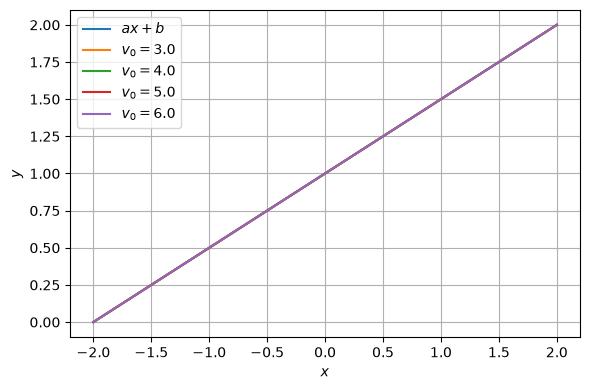

In [16]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値


def calc_v(a,b,v0):
    q = 1 #1+0
    d = -0.5 #phi(0)
    alpha = a/q
    beta = b/d
    tau = np.sign(a)

    v1 = tau*v0
    v2 = beta-v1

    w1 = alpha/v1
    w2 = -alpha/v2
    
    return v1,v2,w1,w2

plt.figure(figsize=(6, 4))
plt.plot(xx,a*xx+b,label=r'$ax+b$') #r文字列はlatex表記でつかうバックスラッシュに対応するために必要

v0 = [3.0,4.0,5.0,6.0]

for v in v0:
    v1,v2,w1,w2 = calc_v(a,b,v)
    print(f'(w1,w2)=({w1:.5f},{w2:.5f}),(v1,v2)=({v1:.5f},{v2:.5f})')
    plt.plot(xx,v1*shifted_relu(w1*xx,0.5)+v2*shifted_relu(-w2*xx,0.5),label=rf'$v_0={v}$')


plt.xlabel(r'$x$')
plt.ylabel(r'$y$')
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig('Sec4_Fig_ShiftedReLU2.pdf', bbox_inches='tight',transparent=True)
plt.show()

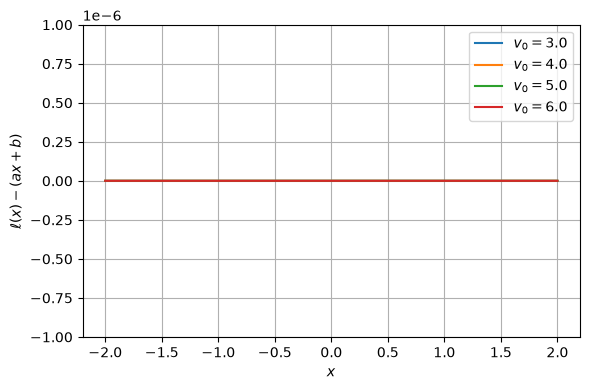

In [17]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値


def calc_v(a,b,v0):
    q = 1 #1+0
    d = -0.5 #phi(0)
    alpha = a/q
    beta = b/d
    tau = np.sign(a)

    v1 = tau*v0
    v2 = beta-v1

    w1 = alpha/v1
    w2 = -alpha/v2

    return v1,v2,w1,w2


v0 = [3.0,4.0,5.0,6.0]

plt.figure(figsize=(6, 4))
for v in v0:
    v1,v2,w1,w2 = calc_v(a,b,v)
    y = v1*shifted_relu(w1*xx,0.5)+v2*shifted_relu(-w2*xx,0.5)
    plt.plot(xx,y-(a*xx+b),label=rf'$v_0={v}$')

plt.ylim(-1e-6,1e-6)
#plt.axhline(0.0, linewidth=1)
plt.xlabel(r'$x$')
plt.ylabel(r'$\ell(x) - (ax+b)$')
plt.grid()
plt.legend()
plt.tight_layout()
plt.savefig('Sec4_Fig_ShiftedReLU3.pdf', bbox_inches='tight',transparent=True)
plt.show()

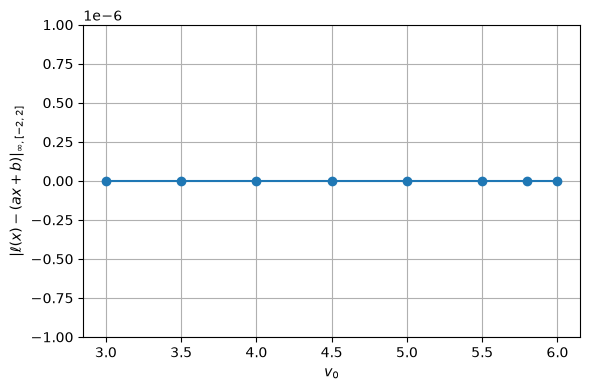

In [18]:
xx = np.linspace(-2,2,4000)

#ターゲットとなるaffineパラメタ
a = 0.5 #傾き
b = 1 #バイアス値


def calc_v(a,b,v0):
    q = 1 #1+0
    d = -0.5 #phi(0)
    alpha = a/q
    beta = b/d
    tau = np.sign(a)

    v1 = tau*v0
    v2 = beta-v1

    w1 = alpha/v1
    w2 = -alpha/v2

    return v1,v2,w1,w2


v0 = [3.0,3.5,4.0,4.5,5.0,5.5,5.8,6.0]

errors=[]
for v in v0:
    v1,v2,w1,w2 = calc_v(a,b,v)
    y = v1*shifted_relu(w1*xx,0.5)+v2*shifted_relu(-w2*xx,0.5)
    err = np.max(np.abs(y-(a*xx+b)))
    errors.append(err)

errors = np.array(errors)

plt.figure(figsize=(6, 4))
plt.plot(v0, errors, marker='o')
plt.ylim(-1e-6,1e-6)
plt.xlabel(r'$v_0$')
plt.ylabel(r'$|\ell(x)-(ax+b)|_{\infty,[-2,2]}$')
#plt.title(r'Supremum error versus scaling parameter $w$')
plt.grid(True)
plt.tight_layout()
plt.savefig('Sec4_Fig_ShiftedReLU4.pdf', bbox_inches='tight',transparent=True)
plt.show()